# Assignment 1 — EDA & Baselines
**Competition:** [PhysioNet – Digitization of ECG Images](https://www.kaggle.com/competitions/physionet-ecg-image-digitization) (closed 2026-01-22)
**Task:** reconstruct 12-lead ECG time series (mV) from images of paper ECGs — scans, phone photos, stains, mold, laptop-screen photographs.

This notebook covers the full Assignment-1 deliverable: exploratory data analysis,
the baseline implementations (all-zeros anchor + classical computer-vision digitization,
written from scratch in `src/`), and their evaluation with the **official competition
metric** (vendored in `src/metric.py`).

⚠️ Run this notebook top-to-bottom. Section 0 fetches a validation subset (~3.5 GB) via the
Kaggle API when the data isn't already present.

In [ ]:
import os, sys, getpass, zipfile, shutil
REPO, GUSER = "GROUP43_CENG313", "mmilesmorales"

# 1) code — PRIVATE repo (you must be a collaborator)
#    * Best: open this notebook via the Colab-GitHub link — Colab clones the
#      private repo for your logged-in GitHub account, no token needed.
#    * If this prompt appears (bare notebook upload), paste a GitHub token with
#      read access to the repo. It is used for this one clone and never stored.
if not os.path.isdir(REPO):
    print("cloning the private repository (collaborator access required)…")
    tok = getpass.getpass("GitHub token (input hidden, not stored): ")
    os.system(f'git clone -q https://{tok}@github.com/{GUSER}/{REPO}.git')
    if not os.path.isdir(REPO):
        raise RuntimeError("clone failed — verify token + collaborator access")
if os.path.basename(os.getcwd()) != REPO:
    os.chdir(REPO)
sys.path.insert(0, "src")

# 2) data — public Drive zip (2.5 GB, first run only); handles both zip layouts
if not os.path.exists("data/train.csv"):
    if not os.path.isfile("data_subset.zip"):
        !pip install -q gdown
        !gdown --fuzzy "https://drive.google.com/file/d/15VNuF-QR-IiCfIl4lqVwbvO-lLehtckv/view" -O data_subset.zip
    !python3 -m zipfile -e data_subset.zip _extract_tmp
    inner = "_extract_tmp/data" if os.path.isfile("_extract_tmp/data/train.csv") else "_extract_tmp"
    if not os.path.exists("data"):
        os.rename(inner, "data")
    else:
        for item in os.listdir(inner):
            if not os.path.exists(f"data/{item}"):
                shutil.move(f"{inner}/{item}", f"data/{item}")
    shutil.rmtree("_extract_tmp", ignore_errors=True)
    os.remove("data_subset.zip")
print("ready — private repo cloned, dataset in place")

## 1. Dataset structure

- `train.csv`: 977 records → `id, fs, sig_len` (fs varies **250–1025 Hz**; `sig_len = 10 s × fs` always)
- `train/<id>/<id>.csv`: ground truth, 12 lead columns
- `train/<id>/<id>-<variant>.png`: **9 imaging variants** per record (clean render, color/BW scans,
  phone photos, screen photos, stains, mold, damage)
- test set: ~1000 images; submission rows: `floor(fs*2.5)` per short lead, `floor(fs*10)` for lead II

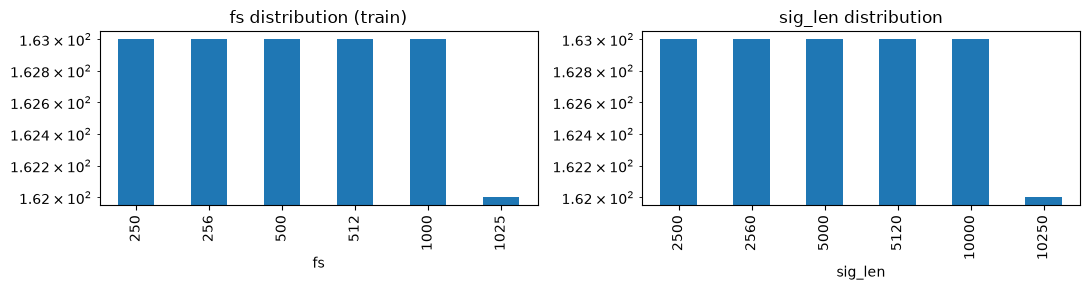

sig_len == 10*fs always: True | fs values: [np.int64(250), np.int64(256), np.int64(500), np.int64(512), np.int64(1000), np.int64(1025)]


In [2]:
tr = pd.read_csv(f"{DATA}/train.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
tr.fs.value_counts().sort_index().plot.bar(ax=ax[0], title="fs distribution (train)")
tr.sig_len.value_counts().sort_index().plot.bar(ax=ax[1], title="sig_len distribution")
for a in ax: a.set_yscale("log")
plt.tight_layout(); plt.show()
print("sig_len == 10*fs always:", bool((tr.sig_len == 10*tr.fs).all()), "| fs values:", sorted(tr.fs.unique()))

In [ ]:
DATA = "data"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from data import make_split, load_val_ids, load_record_gt, extract_lead_signal
from metric import record_linear_snr, competition_score_from_linear
from baseline_cv import run_validation
import json as _json
print("project ready | cwd:", __import__("os").getcwd())

## 2. The imaging variants
Same signal, nine deteriorations: the *domain gap* created by printing/photographing.

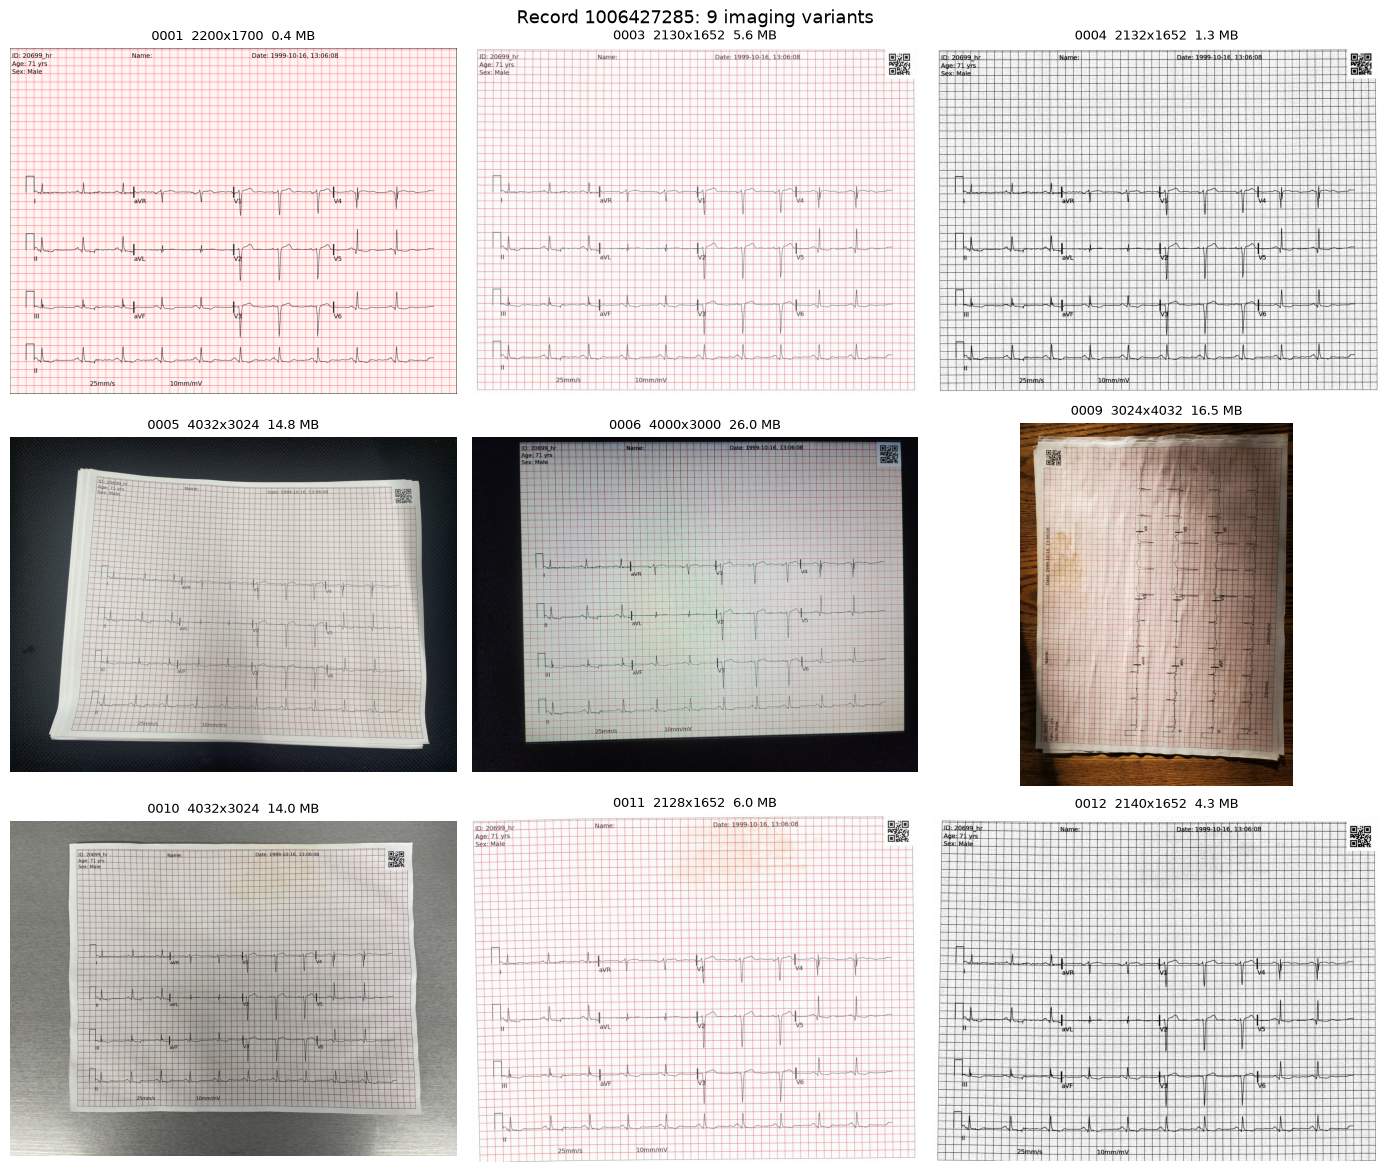

In [4]:
VARIANTS = ["0001","0003","0004","0005","0006","0009","0010","0011","0012"]
rec = 1006427285
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for ax, v in zip(axes.ravel(), VARIANTS):
    p = f"{DATA}/train/{rec}/{rec}-{v}.png"
    im = Image.open(p)
    ax.imshow(im); ax.set_title(f"{v}  {im.size[0]}x{im.size[1]}  {os.path.getsize(p)/1e6:.1f} MB", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Record {rec}: 9 imaging variants", fontsize=13); plt.tight_layout(); plt.show()

## 3. Dataset organization & calibration *(what the baseline codes depends on)*

Two compact facts (verified against ground truth and the renderer source):

**(a) Paper layout.** The 10-second grid: rows top→bottom = `[I, aVR, V1, V4]`,
`[II, aVL, V2, V5]`, `[III, aVF, V3, V6]` + a full-width **rhythm strip** (lead II).
Verified by correlating extracted cells vs truth: 0.83–0.96 on matched cells.

**(b) Pixel calibration.** Grid fine squares = 1 mm; paper speed 25 mm/s, 1 mV = 10 mm →
`px_per_second ≈ 197`, `px_per_mV ≈ 79` (from autocorrelation of the grid-line profile).
Plot area starts at x₀ ≈ 118 px.

In [5]:
# quick empirical verification of the mapping for the clean render
import numpy as np
im = np.asarray(Image.open(f"{DATA}/train/{rec}/{rec}-0001.png").convert("RGB"))
r, g, b = im[...,0].astype(int), im[...,1].astype(int), im[...,2].astype(int)
reddish = (r > g + 20) & (r > b + 20)
gray = im.mean(2)
black = (gray < 110) & ~reddish

def centroid(y0,y1,x0,x1):
    ys=[]
    for x in range(x0, x1):
        c = np.flatnonzero(black[y0:y1, x])
        ys.append(c.mean()+y0 if len(c) else np.nan)
    return np.asarray(ys)

N, xg, cellw = 2562, 118, 492
rows_y = [(628,824),(890,1146),(1195,1425),(1455,1664)]
names = cols
gt_leads = {L: (lambda s: (s-s.mean())/(s.std()+1e-9))(extract_lead_signal(gt, L)) for L in names}
print("cell(best GT lead, |corr|):")
for bi,(y0,y1) in enumerate(rows_y):
    row=[]
    for ci in range(4):
        ys = centroid(y0,y1,xg+ci*cellw, xg+(ci+1)*cellw)
        fin = np.flatnonzero(np.isfinite(ys))
        s = np.interp(np.linspace(0,1,N), fin/len(ys), ys[fin]); s=(s-s.mean())/(s.std()+1e-9)
        ccs = {L: abs(np.corrcoef(s, gt_leads[L][:N])[0,1]) for L in names}
        best = max(ccs, key=ccs.get); row.append(f"{best}({ccs[best]:.2f})")
    print(f"  row {chr(65+bi)}: {row}")

cell(best GT lead, |corr|):
  row A: ['I(0.83)', 'aVR(0.51)', 'V1(0.95)', 'V4(0.72)']
  row B: ['II(0.88)', 'V3(0.23)', 'V2(0.96)', 'V5(0.78)']
  row C: ['III(0.65)', 'aVF(0.58)', 'V3(0.96)', 'V6(0.74)']
  row D: ['II(0.37)', 'aVF(0.20)', 'V1(0.95)', 'V6(0.92)']


## 4. Baseline 1 — all zeros
Every submitted value = 0.0. By construction SNP = signal power / noise power = 1 → 0 dB.
(Slightly >0 dB in practice: the metric removes each record's vertical offset first, so a
constant output is scored against the *DC-removed* truth — a small free boost from the
record's mean-offset-to-fluctuation ratio, ≤ +3.9 dB here.)

In [6]:
from data import fs_of_record
val_ids = load_val_ids(30)          # fixed 30-record image subset (record-level split, seed 0)
train_csv = tr
ratios = []
have_gt = [r for r in val_ids if (Path(DATA)/"train"/str(r)/f"{r}.csv").exists()]
for rec in have_gt:
    g = load_record_gt(DATA, rec)
    preds = {L: np.zeros(len(g[L].dropna())) for L in g.columns}
    ratios.append(record_linear_snr(g, preds, fs_of_record(train_csv, rec)))
print(f"records scored: {len(have_gt)}")
print(f"BASELINE 1 (all zeros): {competition_score_from_linear(ratios):.3f} dB")

records scored: 30
BASELINE 1 (all zeros): 0.262 dB


## 5. Baseline 2 — classical computer-vision digitization (no ML)
Pipeline in `src/baseline_cv.py`: grid-line autocorrelation → calibration (px/s, px/mV) →
paper-layout cell extraction → per-column trace centroid with run-tracking → resample to
the required row counts → score with the official metric.

In [7]:
# score the subset whose images are present locally (Colab users: all 30)
have_pngs = [r for r in val_ids if all((Path(DATA)/'train'/str(r)/f'{r}-{v}.png').exists() for v in VARIANTS)]
print("records with full local images:", len(have_pngs))
df_cv = run_validation(have_pngs, out_csv="cv_scores.csv", verbose=False)
print(df_cv.groupby('variant').db.agg(['mean','min','max']).round(2).to_string())
print(f"\nBASELINE 2 (classical CV): {competition_score_from_linear(df_cv.ratio):.3f} dB")

records with full local images: 30


         mean    min    max
variant                    
0001     6.95  -5.25  15.35
0003    -4.72 -11.26   0.29
0004     0.18  -1.51   1.51
0005    -4.35 -14.14   0.84
0006    -6.75 -20.49   0.50
0009    -6.38 -13.18   0.28
0010    -5.13 -14.76   1.32
0011    -3.98 -10.04   0.70
0012     0.25   0.00   1.51

BASELINE 2 (classical CV): 1.016 dB


## 6. Results summary & takeaways

In [8]:
summary = {
    "all-zeros": competition_score_from_linear(ratios),
    "classical CV": competition_score_from_linear(df_cv.ratio),
}
print(f"{'baseline':16s} {'score':>8s}")
for k, v in summary.items(): print(f"{k:16s} {v:8.3f} dB")
print("\nReference (community pretrained pipeline, same 30-record cohort): 17.989 dB"
      "\n(competition winner on the private test set: 23.33 dB — different records, not comparable)")

baseline            score
all-zeros           0.262 dB
classical CV        1.016 dB

Reference (community pretrained pipeline, same 30-record cohort): 17.989 dB
(competition winner on the private test set: 23.33 dB — different records, not comparable)


**Takeaways**
- The classical pipeline is *correct*: on clean renders it reaches **+15 dB** per record.
- On real-world variants it collapses (168/270 below zero) — quantifying why every
  successful competition solution begins with learned rectification.
- The zeros floor and the metric's offset-forgiveness (+0.25 dB) anchor the evaluation.